# Terraria: redes de fabricação e obtenção

Este trabalho usa dados do [Terraria Progress Tracker](https://github.com/Doeschi/Terraria-Progress-Tracker/tree/e1726af0908d928a3e2fa437286558827a6dd3b0/pipeline/data_readable), versão 1.4.5, para estudar as perguntas de [LEIA.md](../docs/LEIA.md). `G` descreve relações do jogo; `H` resume apenas ligações de fabricação para análise de redes. A conectividade representa relações possíveis, não uma simulação de jogo.

In [1]:
import json
import random
from pathlib import Path
from collections import Counter

import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display, Markdown

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data/raw/items.json").exists())
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})

In [2]:
names = ["items", "recipes", "bosses", "biomes", "milestones", "drops", "conditions", "bestiary", "events", "vendors", "shops"]
data = {}
for name in names:
    data[name] = json.loads((root / "data/raw" / f"{name}.json").read_text(encoding="utf-8"))
items = {item["key"]: item for item in data["items"]}
recipes = data["recipes"]["recipes"]
bosses = {boss["id"]: boss for boss in data["bosses"]["bosses"]}
biomes = {biome["id"]: biome for biome in data["biomes"]}
milestones = {mark["id"]: mark for mark in data["milestones"]}
vendors = {vendor["id"]: vendor for vendor in data["vendors"]}

In [3]:
display(pd.DataFrame([{"arquivo": name, "entradas ou seções": len(data[name]),
                       "campos": ", ".join(list(data[name][0] if isinstance(data[name], list) else data[name])[:8])}
                      for name in names]))

,arquivo,entradas ou seções,campos
0,items,6186,"key, id, name, internalName, page, url, icon, ..."
1,recipes,4,"stations, groups, recipes, shimmer"
2,bosses,3,"stages, bosses, ignoreItems"
3,biomes,18,"id, name, icon, count"
4,milestones,16,"id, name, icon, count"
5,drops,4,"sources, items, groups, areas"
6,conditions,2,"groups, conditions"
7,bestiary,2,"types, entries"
8,events,18,"id, name, icon, count"
9,vendors,24,"id, name, icon, count, head"


## Construção de G

Identificadores têm prefixos. Receitas distintas são alternativas; seus **slots são simultâneos** e as opções dentro de cada slot são alternativas. Estações listadas na receita são requisitos conjuntos, e itens que fornecem uma mesma estação são alternativas. Nós de rota separam ofertas e linhas de drop, inclusive suas condições. Os tokens são mantidos com o texto original: sua lista isolada não estabelece se são alternativas ou requisitos conjuntos. Arestas paralelas preservam o número do slot e outras ocorrências. Consulte os atributos de cada rota para probabilidades e texto original. Não confunda um caminho individual com uma receita completa.

In [4]:
groups = data["recipes"]["groups"]
stations = data["recipes"]["stations"]
ETAPAS = {"pre-hardmode": "pré-Hardmode", "hardmode": "Hardmode", "event": "evento"}

def desktop(record):
    return "desktop" in record.get("platforms", ["desktop"])

def options(slot):
    if "item" in slot:
        return [slot["item"]]
    return groups[slot["group"]]["items"]

G = nx.MultiDiGraph()
def entity(node, name, kind, **attributes):
    G.add_node(node, name=name, type=kind, **attributes)

def relation(origin, destination, name, **attributes):
    if origin not in G or destination not in G:
        raise ValueError(f"Referência ausente: {origin} → {destination} ({name})")
    G.add_edge(origin, destination, relation=name, **attributes)

for key, item in items.items():
    if desktop(item):
        entity(f"item:{key}", item["name"], "item")
# Os 32 bosses compartilham um tipo e uma cor; a etapa de bosses.json fica no rótulo e no atributo.
for boss in bosses.values():
    entity(f"boss:{boss['id']}", f"{boss['name']}\nboss · {ETAPAS[boss['stage']]}", "boss",
           etapa=boss["stage"])
for kind, records in [("biome", biomes.values()), ("milestone", milestones.values()),
                      ("event", data["events"]), ("npc", data["vendors"]),
                      ("condition", data["conditions"]["conditions"])]:
    for record in records:
        entity(f"{kind}:{record['id']}", record["name"], kind)


In [5]:
for name, station in stations.items():
    kind = "condition" if station.get("condition") else "station"
    entity(f"{kind}:{name}", name, kind)
    for item_key in station.get("items", []):
        assert item_key in items
        if f"item:{item_key}" in G:
            relation(f"item:{item_key}", f"{kind}:{name}", "fornece estação", escolha="alternativa")

for index, recipe in enumerate(recipes):
    assert recipe["result"] in items and recipe["stations"] is not None
    for slot in recipe["ingredients"]:
        assert options(slot) and all(key in items for key in options(slot))

def viavel(recipe):
    return (desktop(recipe) and f"item:{recipe['result']}" in G
            and all(any(f"item:{key}" in G for key in options(slot)) for slot in recipe["ingredients"]))

# O índice da lista não identifica nada: o rótulo traz produto, quantidade e estação.
aceitas = [index for index, recipe in enumerate(recipes) if viavel(recipe)]
alternativas = Counter(recipes[index]["result"] for index in aceitas)

def rotulo_receita(recipe, posicao):
    produto = items[recipe["result"]]["name"]
    quantidade = f" ×{recipe['amount']}" if recipe["amount"] > 1 else ""
    # Estações na mesma receita são exigidas juntas, como Loom + Ecto Mist.
    estacao = " + ".join(recipe["stations"])
    total = alternativas[recipe["result"]]
    variante = f" · alt. {posicao}/{total}" if total > 1 else ""
    return f"{produto}{quantidade}\n⚒ {estacao}{variante}"

ordinal = Counter()
for index in aceitas:
    recipe = recipes[index]
    ordinal[recipe["result"]] += 1
    node = f"recipe:{index}"
    entity(node, rotulo_receita(recipe, ordinal[recipe["result"]]), "recipe",
           produto=recipe["result"], indice=index, dados=recipe)
    relation(node, f"item:{recipe['result']}", "produz", quantidade=recipe["amount"])
    for slot_number, slot in enumerate(recipe["ingredients"]):
        for key in options(slot):
            if f"item:{key}" in G:
                relation(f"item:{key}", node, "ingrediente", slot=slot_number,
                         quantidade=slot["amount"], grupo=slot.get("group"))
    for name in recipe["stations"]:
        assert name in stations
        kind = "condition" if stations[name].get("condition") else "station"
        relation(f"{kind}:{name}", node, "requisito de fabricação")


In [6]:
def rotulo_rota(prefixo, detalhe):
    return f"{prefixo}\n{detalhe}" if detalhe else prefixo

def taxa_curta(row):
    # O campo `rate` chega a 83 caracteres; o texto completo permanece em `dados`.
    taxa = (row.get("rate") or "").split(" · ")[0].strip()
    return taxa if len(taxa) <= 20 else taxa[:19] + "…"

sources = data["drops"]["sources"]
TIPO_FONTE = {"npc": "enemy", "bag": "bag", "container": "container"}

def tipo_da_fonte(source_id):
    """Boss tem nó próprio; sacola e contêiner ficam em tipos distintos para não esconder baús."""
    source = sources[source_id]
    if source_id in bosses and source["kind"] == "npc":
        return "boss"
    return TIPO_FONTE[source["kind"]]

# Uma fonte sem identificação segura no bestiário permanece uma fonte própria.
for source_id, source in sources.items():
    if not desktop(source):
        continue
    kind = tipo_da_fonte(source_id)
    node = f"{kind}:{source_id}"
    if kind != "boss":
        entity(node, source["name"], kind, origem=source["kind"])
    for field, contexto in [("biomes", "biome"), ("events", "event")]:
        for value in source.get(field, []):
            relation(f"{contexto}:{value}", node, "encontro associado")

for boss_id, boss in bosses.items():
    for source_id in boss["sources"]:
        assert source_id in sources
        if desktop(sources[source_id]) and source_id != boss_id:
            relation(f"boss:{boss_id}", f"{tipo_da_fonte(source_id)}:{source_id}",
                     "agrupa fonte", origem="bosses.json")

for item_key, rows in data["drops"]["items"].items():
    assert item_key in items
    for index, row in enumerate(rows):
        assert row["source"] in sources
        source = sources[row["source"]]
        if f"item:{item_key}" not in G or not desktop(source):
            continue
        route = f"drop:{item_key}:{index}"
        entity(route, rotulo_rota("Drop", taxa_curta(row)), "drop",
               item=item_key, fonte=row["source"], dados=row)
        relation(f"{tipo_da_fonte(row['source'])}:{row['source']}", route, "fonte do drop")
        relation(route, f"item:{item_key}", "obtém item")
        for condition in row.get("conditions", []):
            relation(f"condition:{condition}", route, "condição da rota")
        for biome in row.get("biomes", []):
            relation(f"biome:{biome}", route, "contexto da rota")


In [7]:
for item_key, rows in data["shops"].items():
    assert item_key in items
    if f"item:{item_key}" not in G:
        continue
    for index, row in enumerate(rows):
        route = f"sale:{item_key}:{index}"
        entity(route, rotulo_rota("Oferta", vendors[row["vendor"]]["name"]), "sale",
               item=item_key, fonte=row["vendor"], dados=row)
        relation(f"npc:{row['vendor']}", route, "oferece")
        relation(route, f"item:{item_key}", "vende")
        for condition in row.get("conditions", []):
            relation(f"condition:{condition}", route, "condição da rota")
        for biome in row.get("biomes", []):
            relation(f"biome:{biome}", route, "contexto da rota")

# Shimmer é outra rota, sem misturá-la às receitas.
for index, row in enumerate(data["recipes"]["shimmer"]):
    assert row["result"] in items
    for key in options(row):
        assert key in items
        if f"item:{key}" in G and f"item:{row['result']}" in G:
            relation(f"item:{key}", f"item:{row['result']}", "conversão Shimmer",
                     quantidade=row["amount"], grupo=row.get("group"), dados=row)

for key, item in items.items():
    if f"item:{key}" not in G:
        continue
    if item.get("milestone"):
        relation(f"milestone:{item['milestone']}", f"item:{key}", "disponibilidade estimada",
                 explicacao=item.get("milestoneVia"), origem="items.json")

# As entradas do bestiário mantêm identidade independente das fontes sem junção inequívoca.
for entry in data["bestiary"]["entries"]:
    if not desktop(entry):
        continue
    node = f"bestiary:{entry['id']}"
    entity(node, entry["name"], "bestiary")
    for biome in entry.get("biomes", []):
        relation(f"biome:{biome}", node, "encontro associado")
    for event in entry.get("events", []):
        relation(f"event:{event}", node, "encontro associado")
    # Apenas identificações simultaneamente iguais por nome e npcId são associadas.
    for source_id, source in sources.items():
        if (desktop(source) and source["kind"] == "npc" and source.get("npcId") is not None
                and source.get("npcId") == entry.get("npcId") and source["name"] == entry["name"]):
            relation(node, f"{tipo_da_fonte(source_id)}:{source_id}", "mesma fonte documentada")


## Progressão, aquisição e limites

Os marcos do tracker são estimativas de disponibilidade, **não pré-requisitos universais**. Na pequena tabela abaixo, `qualquer` é OR e `todos` é AND; conquistas opcionais não são ordenadas numa cadeia única. As regras suplementares usam a [wiki oficial: Hardmode](https://terraria.wiki.gg/wiki/Hardmode), [progressão](https://terraria.wiki.gg/wiki/Guide:Game_progression) e [Plantera](https://terraria.wiki.gg/wiki/Plantera). Elas pressupõem progressão normal de um mesmo mundo, não todas as possibilidades entre mundos e seeds. A fonte local associa Mothron a Plantera e a [página da wiki](https://terraria.wiki.gg/wiki/Mothron) registra a nota de versão 1.4.1 do desktop: Mothron só aparece depois de Plantera derrotada. Mantemos a relação como regra desta versão dos dados, ainda assim restrita à progressão normal. Ela entra em `G` como a aresta `boss:plantera → enemy:mothron`, e é por isso que Plantera aparece junto do Mothron no diagrama em vez de flutuar ao lado da Terra Blade.

Os dados não estruturam geração geológica nem a ferramenta de mineração: `milestoneVia` é texto. Para Chlorophyte, mostramos esse texto, sem inventar aresta de mineração ou bioma. Condições de loja pertencem à oferta, não a todos os métodos de aquisição.

In [8]:
progress = {
    "wall-of-flesh": ("todos", ["wall-of-flesh"]),
    "any-mech": ("qualquer", ["the-twins", "the-destroyer", "skeletron-prime"]),
    "all-mechs": ("todos", ["the-twins", "the-destroyer", "skeletron-prime"]),
    "evil-boss": ("qualquer", ["eater-of-worlds", "brain-of-cthulhu"]),
}
for mark in milestones:
    if mark in bosses and mark not in progress:
        progress[mark] = ("todos", [mark])
for mark, (logic, boss_ids) in progress.items():
    G.nodes[f"milestone:{mark}"]["logica_bosses"] = logic
    for boss_id in boss_ids:
        relation(f"boss:{boss_id}", f"milestone:{mark}", "contribui para marco", logica=logic)
relation("milestone:wall-of-flesh", "condition:hardmode", "desbloqueia", fonte="https://terraria.wiki.gg/wiki/Hardmode")
entity("requirement:plantera", "Invocação de Plantera", "requirement")
G.nodes["requirement:plantera"]["logica"] = "todos"
relation("milestone:all-mechs", "requirement:plantera", "requisito", fonte="https://terraria.wiki.gg/wiki/Plantera")
relation("condition:hardmode", "requirement:plantera", "requisito", fonte="https://terraria.wiki.gg/wiki/Hardmode")
relation("requirement:plantera", "boss:plantera", "habilita invocação")
relation("boss:plantera", "enemy:mothron", "habilita aparição",
         fonte="https://terraria.wiki.gg/wiki/Mothron")
relation("milestone:plantera", "boss:golem", "acesso usual ao templo", fonte="https://terraria.wiki.gg/wiki/Guide:Game_progression")
print("Marcos com regras AND/OR:")
display(pd.DataFrame([{"marco": mark, "lógica": logic, "bosses": ", ".join(ids)} for mark, (logic, ids) in progress.items()]))

Marcos com regras AND/OR:


,marco,lógica,bosses
0,wall-of-flesh,todos,wall-of-flesh
1,any-mech,qualquer,"the-twins, the-destroyer, skeletron-prime"
2,all-mechs,todos,"the-twins, the-destroyer, skeletron-prime"
3,evil-boss,qualquer,"eater-of-worlds, brain-of-cthulhu"
4,king-slime,todos,king-slime
5,eye-of-cthulhu,todos,eye-of-cthulhu
6,queen-bee,todos,queen-bee
7,deerclops,todos,deerclops
8,skeletron,todos,skeletron
9,queen-slime,todos,queen-slime


In [9]:
assert len({i["key"] for i in data["items"]}) == len(data["items"])
assert all(info.get("name") and info.get("type") for _, info in G.nodes(data=True))
assert all(edge.get("relation") for *_, edge in G.edges(data=True))
for index, recipe in enumerate(recipes):
    node = f"recipe:{index}"
    if node not in G:
        continue
    for slot_number, slot in enumerate(recipe["ingredients"]):
        expected = {f"item:{key}" for key in options(slot) if f"item:{key}" in G}
        actual = {u for u, _, edge in G.in_edges(node, data=True)
                  if edge["relation"] == "ingrediente" and edge["slot"] == slot_number}
        assert actual == expected
assert G.nodes["milestone:any-mech"]["logica_bosses"] == "qualquer"
assert G.nodes["milestone:all-mechs"]["logica_bosses"] == "todos"
assert G.nodes["milestone:evil-boss"]["logica_bosses"] == "qualquer"
assert G.nodes["requirement:plantera"]["logica"] == "todos"
assert set(G.predecessors("requirement:plantera")) == {"milestone:all-mechs", "condition:hardmode"}
terra_recipe = next(f"recipe:{i}" for i, r in enumerate(recipes) if r["result"] == "TerraBlade" and f"recipe:{i}" in G)
terra_slots = {edge["slot"]: u for u, _, edge in G.in_edges(terra_recipe, data=True) if edge["relation"] == "ingrediente"}
assert set(terra_slots.values()) == {"item:BrokenHeroSword", "item:TrueExcalibur", "item:TrueNightsEdge"}
assert G.has_edge("enemy:mothron", "drop:BrokenHeroSword:0")
assert G.has_edge("boss:plantera", "enemy:mothron") and G.nodes["boss:plantera"]["etapa"] == "hardmode"
assert G.nodes["bag:treasure-bag-plantera"]["type"] == "bag"
assert G.nodes["container:gold-chest-dungeon"]["type"] == "container"
assert G.has_edge("event:solar-eclipse", "enemy:mothron")
assert G.has_edge("biome:jungle", "enemy:giant-tortoise")
leaf = G.nodes["sale:LeafWings:0"]["dados"]
assert {"hardmode", "night", "after-plantera"} <= set(leaf["conditions"]) and "jungle" in leaf["biomes"]
display(pd.DataFrame(Counter(info["type"] for _, info in G.nodes(data=True)).items(), columns=["tipo", "vértices"]))
print(f"G: {G.number_of_nodes():,} vértices e {G.number_of_edges():,} relações")

,tipo,vértices
0,item,6184
1,boss,32
2,biome,18
3,milestone,16
4,event,18
5,npc,24
6,condition,75
7,station,35
8,recipe,3655
9,enemy,368


G: 15,553 vértices e 32,362 relações


## Como o jogo progride, segundo as wikis

A progressão do Terraria é uma escada de bosses que libera materiais e estações; não é uma ordem única de itens. O resumo abaixo vem das páginas listadas no [README](../README.md) e serve para ler as figuras e os marcos de `items.json`.

| Etapa | Portão | O que passa a existir |
|---|---|---|
| Pré-Hardmode inicial | — | Copper, Iron, Silver e Gold; Work Bench, Furnace e Iron/Lead Anvil |
| Pré-Hardmode médio | Eye of Cthulhu, Eater of Worlds **ou** Brain of Cthulhu, Skeletron | Demonite/Crimtane, Meteorite, Hellstone e Hellforge; Demon/Crimson Altar |
| Hardmode | **Wall of Flesh** | Cobalt/Palladium → Mythril/Orichalcum → Adamantite/Titanium, cada minério exigindo a picareta do nível anterior; Mythril/Orichalcum Anvil e Adamantite/Titanium Forge |
| Pós-mecânicos | The Twins, The Destroyer e Skeletron Prime | Hallowed Bar e Souls of Sight, Might e Fright; Drax ou Pickaxe Axe, únicas ferramentas capazes de minerar Chlorophyte |
| Pós-Plantera | **Plantera** | Jungle Temple e Golem; Mothron passa a aparecer no Solar Eclipse |
| Fim de jogo | Lunatic Cultist e eventos lunares | Luminite, Ancient Manipulator e Moon Lord |

A cadeia da Terra Blade atravessa essa escada inteira, e é por isso que ela serve de exemplo: Hellstone e Demonite/Crimtane são pré-Hardmode, a Hallowed Bar exige os três mecânicos, o Chlorophyte exige a picareta que esses mesmos bosses liberam e a Broken Hero Sword exige Plantera.

A pesquisa também confirma duas decisões do modelo. As opções dentro de um slot correspondem aos grupos de ingredientes alternativos documentados pelo jogo, como `Any Wood` e `Any Iron Bar`, e por isso são alternativas reais e não suposição nossa. O Shimmer não é receita e sim transmutação por imersão, e por isso continua em arestas próprias, fora de `recipe:`.

Para consultar qualquer vértice sem abrir os JSONs, as duas funções abaixo imprimem o conteúdo: `descrever` mostra as relações de entrada e saída de um vértice e `receitas_de` lista todas as receitas que produzem um item. O exemplo usa `recipe:3234`, que antes aparecia na figura apenas como `Receita 3234`.


In [10]:
def legivel(node):
    return G.nodes[node]["name"].replace("\n", " ")

def descrever(node):
    """Cartão de um vértice: responde 'que receita ou rota é essa?' sem abrir os JSONs."""
    info = G.nodes[node]
    linhas = [{"direção": "entra", "relação": edge["relation"], "vértice": u, "nome": legivel(u),
               "quantidade": edge.get("quantidade"), "slot": edge.get("slot")}
              for u, _, edge in G.in_edges(node, data=True)]
    linhas += [{"direção": "sai", "relação": edge["relation"], "vértice": v, "nome": legivel(v),
                "quantidade": edge.get("quantidade"), "slot": edge.get("slot")}
               for _, v, edge in G.out_edges(node, data=True)]
    display(Markdown(f"**{node}** — {legivel(node)} (tipo: `{info['type']}`)"))
    display(pd.DataFrame(linhas).sort_values(["direção", "relação", "slot"], na_position="last"))
    if info.get("dados"):
        print("dados originais:", json.dumps(info["dados"], ensure_ascii=False))

def receitas_de(item_key):
    """Todas as receitas de G que produzem o item, com ingredientes por slot."""
    linhas = []
    for node in G.predecessors(f"item:{item_key}"):
        if G.nodes[node]["type"] != "recipe":
            continue
        recipe = G.nodes[node]["dados"]
        linhas.append({"vértice": node, "produz": f"{items[recipe['result']]['name']} ×{recipe['amount']}",
                       "estação": " + ".join(recipe["stations"]),
                       "ingredientes": " + ".join(f"{slot['amount']}× " + " ou ".join(items[k]["name"] for k in options(slot))
                                                  for slot in recipe["ingredients"])})
    return pd.DataFrame(linhas).sort_values("vértice")

descrever("recipe:3234")
display(receitas_de("TerraBlade"))


**recipe:3234** — Onyx Blaster ⚒ Mythril Anvil (tipo: `recipe`)

,direção,relação,vértice,nome,quantidade,slot
0,entra,ingrediente,item:DarkShard,Dark Shard,2.0,0.0
1,entra,ingrediente,item:Shotgun,Shotgun,1.0,1.0
2,entra,ingrediente,item:SoulofNight,Soul of Night,10.0,2.0
3,entra,requisito de fabricação,station:Mythril Anvil,Mythril Anvil,NaN,NaN
4,sai,produz,item:OnyxBlaster,Onyx Blaster,1.0,NaN


dados originais: {"result": "OnyxBlaster", "amount": 1, "stations": ["Mythril Anvil"], "ingredients": [{"item": "DarkShard", "amount": 2}, {"item": "Shotgun", "amount": 1}, {"item": "SoulofNight", "amount": 10}]}


,vértice,produz,estação,ingredientes
0,recipe:3177,Terra Blade ×1,Mythril Anvil,1× Broken Hero Sword + 1× True Excalibur + 1× ...


## Exemplos de dependências

O diagrama é desenhado em camadas: o item-alvo fica no topo e cada nível abaixo está a um passo dirigido de distância dele, então matérias-primas e bosses ficam na base. Além da cadeia de fabricação inteira, a figura traz a fonte de cada item — drops, baús e vendedores, com o boss ou inimigo que os entrega. Sacolas de tesouro são omitidas do desenho porque repetem o drop do próprio boss, mas continuam em `G` como tipo `bag`.

Cores e formas são fixas em todas as figuras:

| Tipo | Cor | Forma |
|---|---|---|
| item | azul-claro | círculo |
| receita | âmbar, com produto, quantidade e estação | retângulo |
| **boss** | **vermelho, igual para os 32, com a etapa no rótulo** | **hexágono** |
| inimigo | salmão | círculo |
| contêiner e sacola | cinza | retângulo |
| bioma | verde | retângulo |
| evento | azul-escuro | retângulo |
| NPC vendedor | magenta | retângulo |
| marco que destrava | roxo | losango |
| rota de drop ou de compra | cinza-claro, com a taxa ou o vendedor | retângulo |

A etapa no rótulo do boss vem de `bosses.json` e é `pré-Hardmode`, `Hardmode` ou `evento`; a cor não muda entre etapas, para que todo boss seja reconhecível de imediato. As arestas distinguem o papel da relação: laranja para `produz`, cinza para `ingrediente`, azul-escuro para obtenção, vermelho tracejado para o boss que destrava uma fonte e roxo tracejado para marco. Uma seta de uma opção não dispensa os outros slots. Receitas circulares e alternativas são preservadas, e a tabela seguinte informa relações e limites que não cabem no desenho.

O marco só entra na figura quando é a única explicação de um item, como o Chlorophyte Ore, que não tem receita nem drop e depende dos três bosses mecânicos. Quando o item tem receita ou fonte própria, a estrutura já responde de onde ele vem e o marco seria ruído.


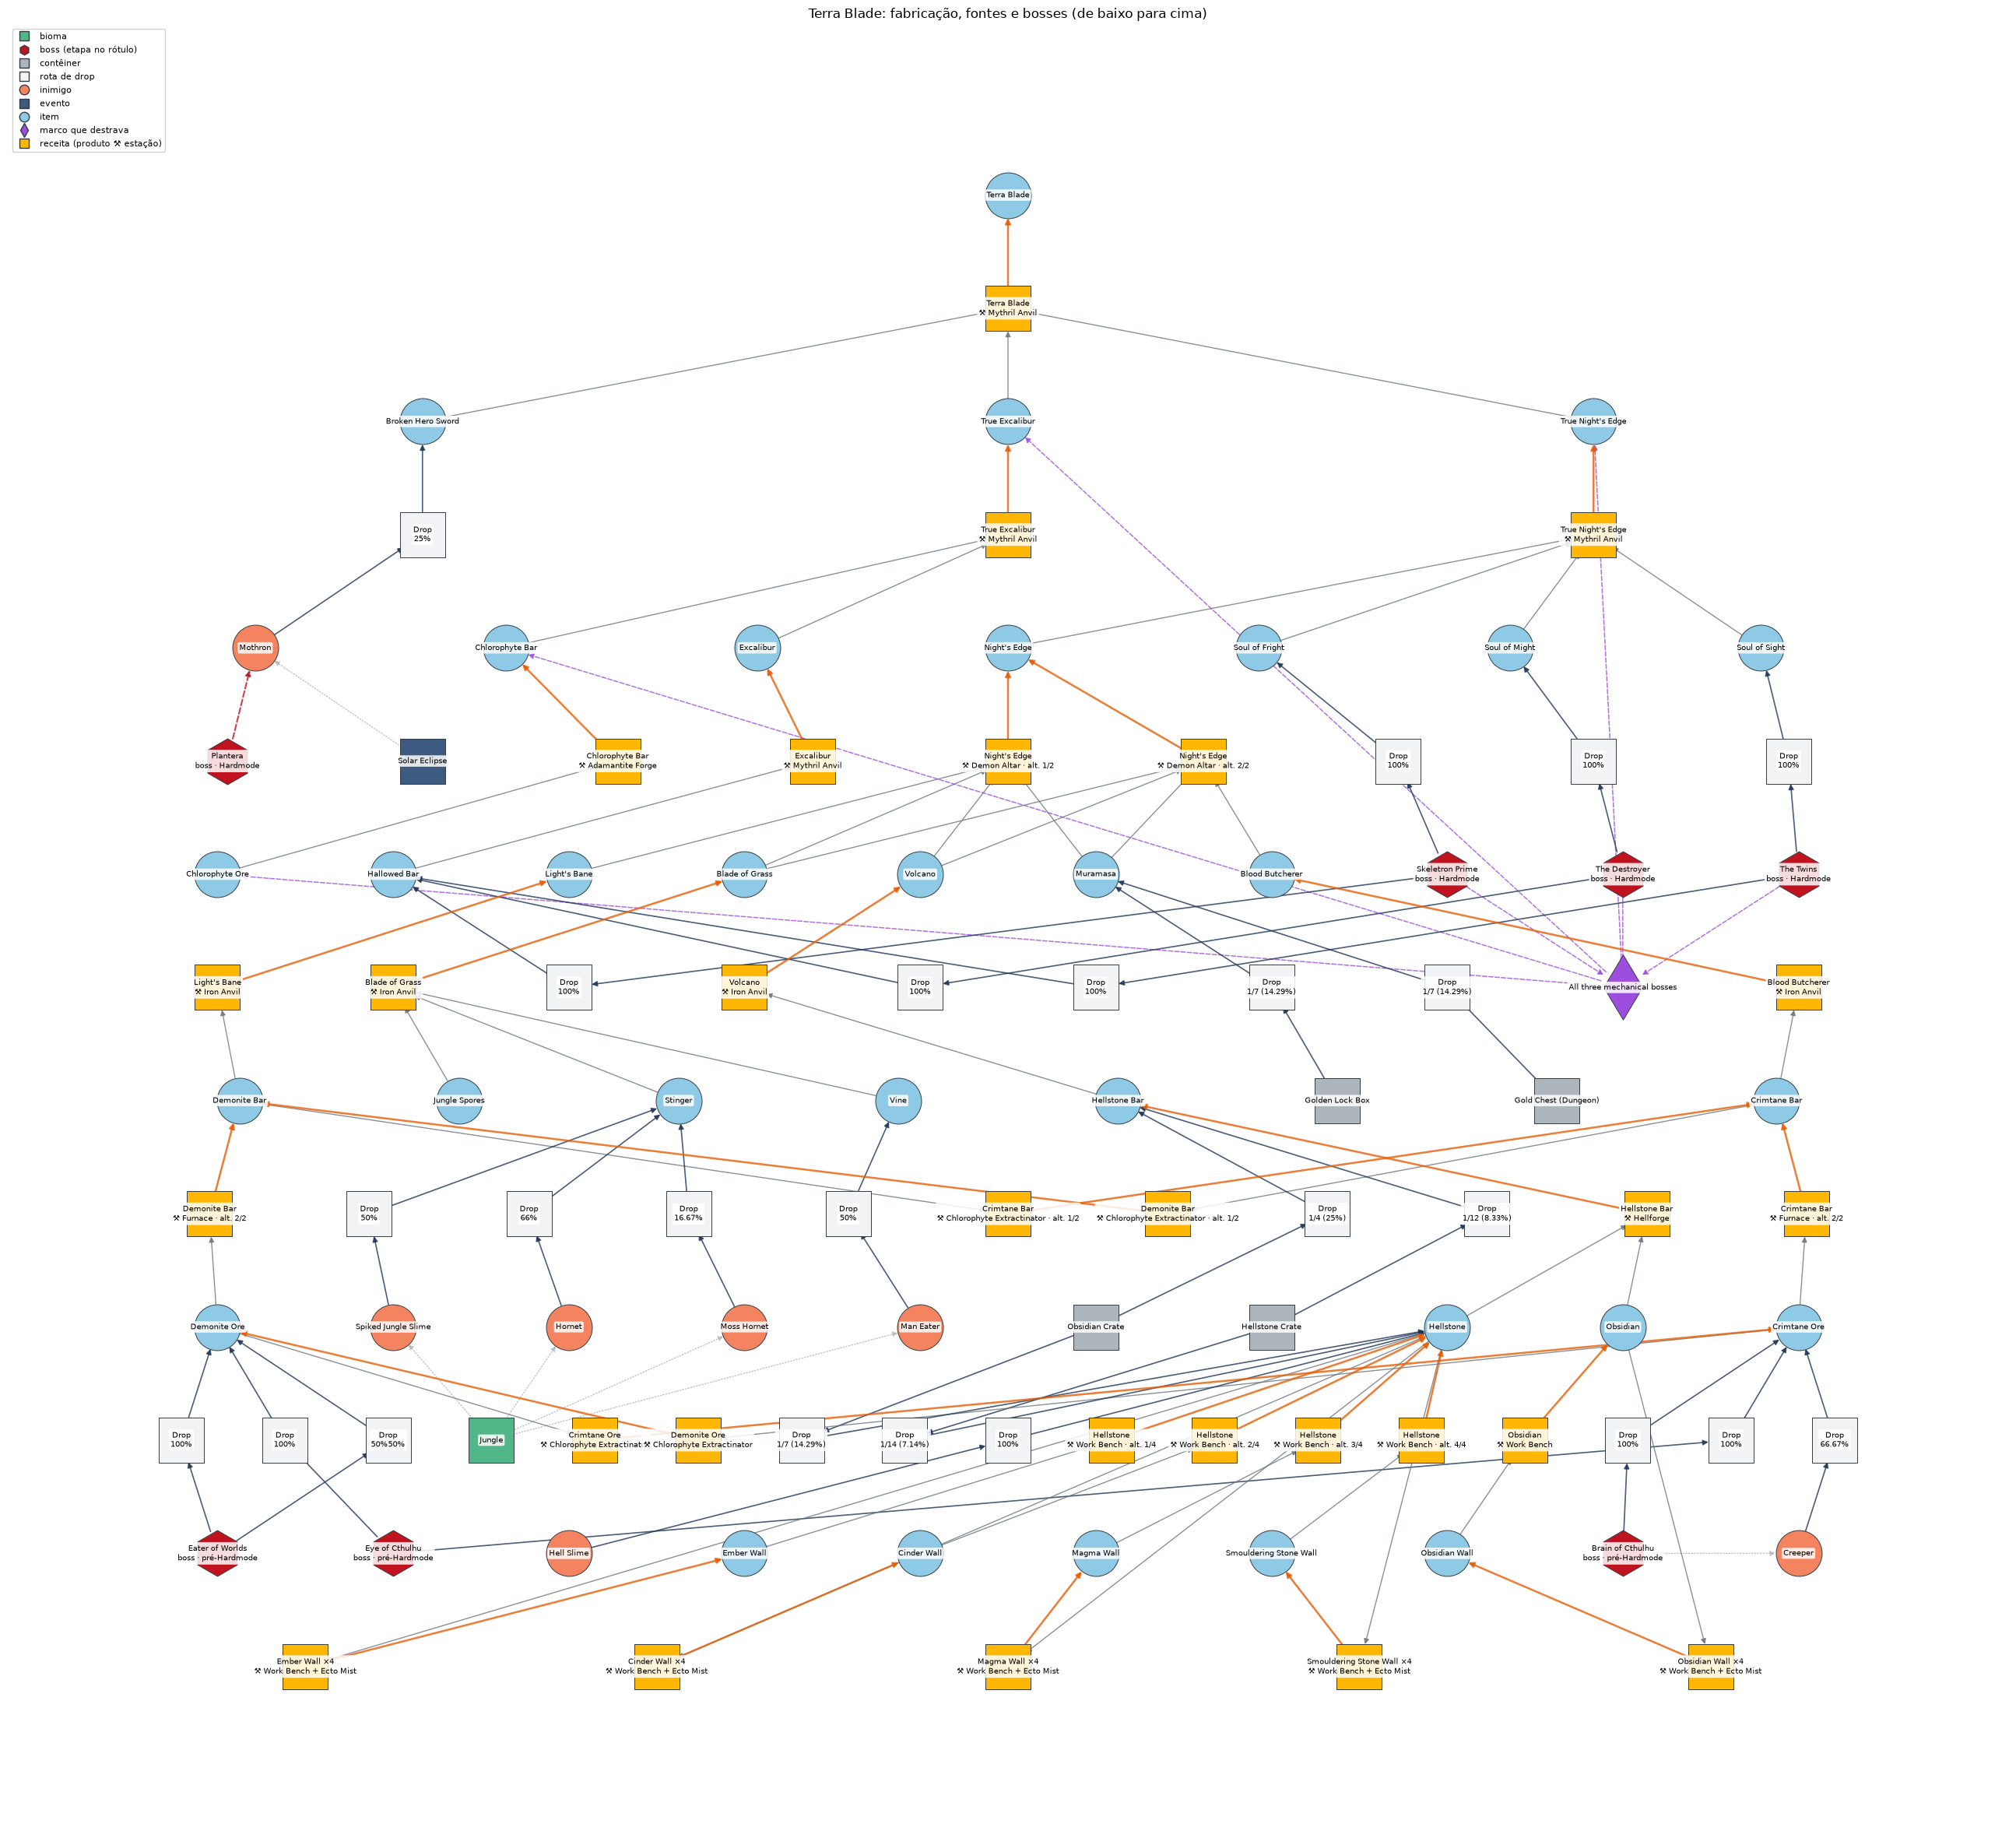

105 vértices em 14 camadas: 32 item, 28 receita, 24 rota de drop, 7 boss, 7 inimigo, 4 contêiner, 1 bioma, 1 evento, 1 marco que destrava


In [11]:
# Paleta fixa: cada tipo tem uma cor e uma forma, e os 32 bosses usam sempre o mesmo vermelho.
CORES = {"item": "#8ecae6", "recipe": "#ffb703", "boss": "#c1121f", "enemy": "#f4845f",
         "container": "#adb5bd", "bag": "#ced4da", "biome": "#52b788", "event": "#3d5a80",
         "npc": "#f72585", "milestone": "#9d4edd", "condition": "#ced4da", "station": "#dee2e6",
         "drop": "#f1f3f5", "sale": "#f1f3f5"}
FORMAS = {"boss": "h", "milestone": "d", "item": "o", "enemy": "o"}
NOMES_TIPO = {"item": "item", "recipe": "receita (produto ⚒ estação)", "boss": "boss (etapa no rótulo)",
              "enemy": "inimigo", "container": "contêiner", "bag": "sacola", "biome": "bioma",
              "event": "evento", "npc": "NPC vendedor", "milestone": "marco que destrava",
              "drop": "rota de drop", "sale": "rota de compra"}
ESTILO_ARESTA = {"produz": ("#e85d04", "solid", 1.8), "ingrediente": ("#6c757d", "solid", 1.0),
                 "obtém item": ("#1d3557", "solid", 1.2), "fonte do drop": ("#1d3557", "solid", 1.2),
                 "disponibilidade estimada": ("#9d4edd", "dashed", 1.1),
                 "contribui para marco": ("#9d4edd", "dashed", 1.1),
                 "habilita aparição": ("#c1121f", "dashed", 1.5)}
ARESTA_PADRAO = ("#adb5bd", "dotted", 1.0)
# Relações que realmente produzem ou entregam o item; marcos apenas anotam disponibilidade.
ESTRUTURAIS = {"ingrediente", "produz", "obtém item", "vende", "fonte do drop", "oferece",
               "agrupa fonte", "encontro associado", "habilita aparição"}

def camadas(graph, target):
    """Camada estrutural é a distância dirigida até o alvo por fabricação e obtenção.
    Marcos e bosses que só anotam progressão não produzem nada e ficam abaixo do que destravam."""
    estrutura = nx.DiGraph()
    estrutura.add_nodes_from(graph)
    estrutura.add_edges_from((u, v) for u, v, edge in graph.edges(data=True)
                             if edge["relation"] in ESTRUTURAIS)
    nivel = nx.single_source_shortest_path_length(estrutura.reverse(copy=True), target)
    vizinhanca = nx.Graph(graph)
    pendentes = [node for node in graph if node not in nivel]
    while pendentes:
        rodada = {node: max(nivel[u] for u in vizinhanca[node] if u in nivel) + 1
                  for node in pendentes if any(u in nivel for u in vizinhanca[node])}
        if not rodada:
            break
        nivel.update(rodada)
        pendentes = [node for node in pendentes if node not in nivel]
    return {node: nivel.get(node, 0) for node in graph}

def posicoes(graph, target):
    """Baricentro dos vizinhos já posicionados reduz cruzamentos sem depender de layout aleatório."""
    nivel = camadas(graph, target)
    vizinhanca = nx.Graph(graph)
    posicao = {}
    for altura in sorted(set(nivel.values())):
        fila = sorted(node for node in graph if nivel[node] == altura)
        fila.sort(key=lambda node: np.mean([posicao[u][0] for u in vizinhanca[node] if u in posicao] or [.5]))
        for coluna, node in enumerate(fila):
            posicao[node] = ((coluna + .5) / len(fila), -altura)
    return posicao, nivel

def selecionar(item_key):
    """Cadeia de fabricação inteira, fontes de cada item e os bosses por trás dessas fontes."""
    target = f"item:{item_key}"
    if target not in G:
        raise KeyError(item_key)
    selected = {target}
    pending = [target]
    while pending:
        node = pending.pop()
        for source, _, edge in G.in_edges(node, data=True):
            if edge["relation"] in {"produz", "ingrediente"} and source not in selected:
                selected.add(source)
                pending.append(source)
    for item in [node for node in selected if G.nodes[node]["type"] == "item"]:
        for rota, _, edge in G.in_edges(item, data=True):
            if edge["relation"] not in {"obtém item", "vende"}:
                continue
            origens = list(G.predecessors(rota))
            # A sacola repete o drop do próprio boss; baú e vendedor são fontes distintas.
            if any(G.nodes[u]["type"] == "bag" for u in origens):
                continue
            selected.add(rota)
            selected.update(origens)
            for origem in origens:
                selected.update(u for u in G.predecessors(origem)
                                if G.nodes[u]["type"] in {"biome", "event"})
        # Item sem receita e sem rota só tem o marco para explicá-lo, como o Chlorophyte Ore.
        if any(G.nodes[u]["type"] in {"recipe", "drop", "sale"} for u in G.predecessors(item)):
            continue
        for marco, _, edge in G.in_edges(item, data=True):
            if edge["relation"] != "disponibilidade estimada":
                continue
            atras = [u for u in G.predecessors(marco) if G.nodes[u]["type"] == "boss"]
            if atras:
                selected.add(marco)
                selected.update(atras)
    # Boss que destrava a aparição de uma fonte selecionada, como Plantera antes do Mothron.
    for origem in [node for node in list(selected) if G.nodes[node]["type"] in {"enemy", "container"}]:
        for boss, _, edge in G.in_edges(origem, data=True):
            if edge["relation"] == "habilita aparição":
                selected.add(boss)
    return target, G.subgraph(selected)

def show_item_graph(item_key):
    target, graph = selecionar(item_key)
    posicao, nivel = posicoes(graph, target)
    largura, fundo = max(Counter(nivel.values()).values()), max(nivel.values()) + 1
    tipos = sorted({G.nodes[node]["type"] for node in graph})
    plt.figure(figsize=(min(26, max(12, largura * 2.1)), min(28, max(6, fundo * 1.7))))
    for tipo in tipos:
        fila = [node for node in graph if G.nodes[node]["type"] == tipo]
        nx.draw_networkx_nodes(graph, posicao, nodelist=fila, node_size=1800,
                               node_color=CORES.get(tipo, "#dee2e6"), node_shape=FORMAS.get(tipo, "s"),
                               edgecolors="#343a40", linewidths=.7)
    for relacao in sorted({edge["relation"] for *_, edge in graph.edges(data=True)}):
        cor, estilo, espessura = ESTILO_ARESTA.get(relacao, ARESTA_PADRAO)
        arestas = sorted({(u, v) for u, v, edge in graph.edges(data=True) if edge["relation"] == relacao})
        nx.draw_networkx_edges(graph, posicao, edgelist=arestas, edge_color=cor, style=estilo,
                               width=espessura, arrowsize=10, node_size=1800, alpha=.8)
    nx.draw_networkx_labels(graph, posicao, labels={node: G.nodes[node]["name"] for node in graph},
                            font_size=7, bbox=dict(boxstyle="round,pad=.22", facecolor="white",
                                                   alpha=.85, linewidth=0))
    plt.legend(handles=[Line2D([], [], linestyle="none", marker=FORMAS.get(tipo, "s"),
                               markerfacecolor=CORES.get(tipo, "#dee2e6"), markeredgecolor="#343a40",
                               markersize=9, label=NOMES_TIPO.get(tipo, tipo)) for tipo in tipos],
               fontsize=8, loc="upper left", framealpha=.9)
    plt.title(f"{items[item_key]['name']}: fabricação, fontes e bosses (de baixo para cima)")
    plt.axis("off")
    plt.margins(.05, .06)
    plt.tight_layout()
    plt.show()
    contagem = Counter(G.nodes[node]["type"] for node in graph)
    print(f"{len(graph)} vértices em {fundo} camadas: "
          + ", ".join(f"{quantidade} {NOMES_TIPO.get(tipo, tipo).split(' (')[0]}"
                      for tipo, quantidade in contagem.most_common()))

show_item_graph("TerraBlade")


,item,marco estimado,explicação da fonte
0,Terra Blade,Plantera,Crafted – needs Broken Hero Sword: Dropped by ...
1,True Night's Edge,All three mechanical bosses,"Crafted – needs Soul of Fright, Soul of Might ..."
2,True Excalibur,All three mechanical bosses,Crafted – needs Chlorophyte Bar → Chlorophyte ...
3,Broken Hero Sword,Plantera,Dropped by Mothron
4,Chlorophyte Ore,All three mechanical bosses,Mined (needs a Pickaxe Axe / Drax)


A receita de True Night's Edge exige as três almas; suas fontes são os três bosses mecânicos.
Mothron → Broken Hero Sword e Solar Eclipse → Mothron são relações estruturadas de drops.json.


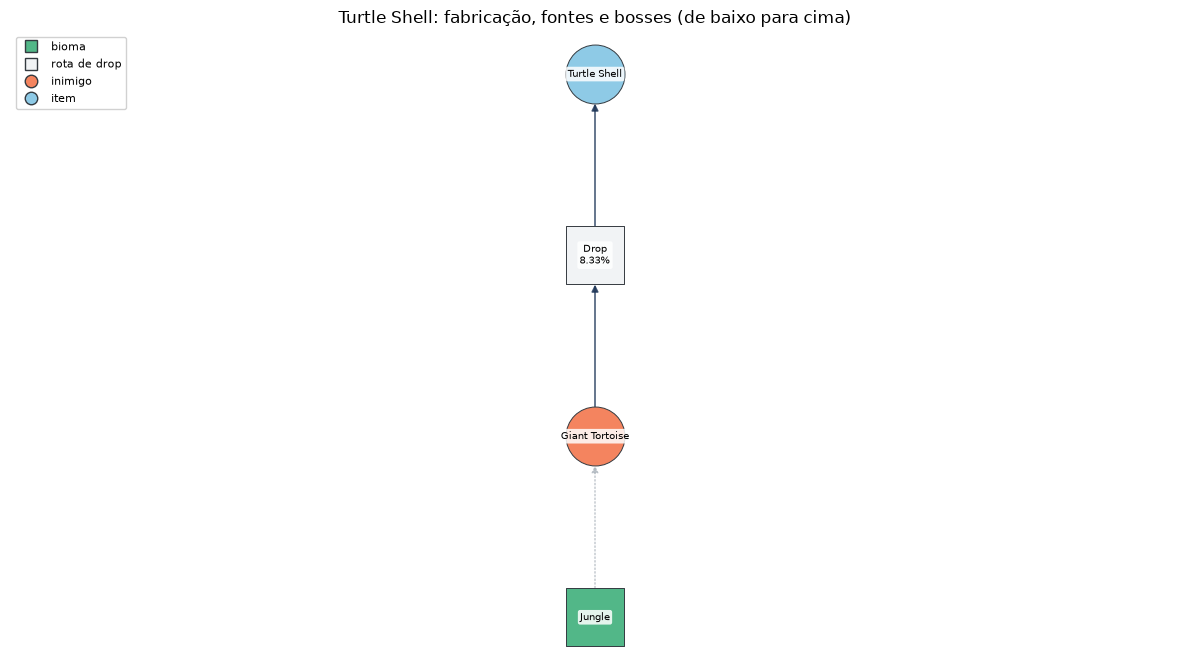

4 vértices em 4 camadas: 1 bioma, 1 item, 1 rota de drop, 1 inimigo


,rota,texto da oferta,tokens,bioma
0,Witch Doctor → Leaf Wings,"In Hardmode, during night, in a Jungle, when P...","hardmode, night, after-plantera",jungle


Nesta oferta, o texto original expressa Hardmode E noite E Jungle E Plantera; outras rotas não herdam estas condições.


In [12]:
keys = ["TerraBlade", "TrueNightsEdge", "TrueExcalibur", "BrokenHeroSword", "ChlorophyteOre"]
display(pd.DataFrame([{"item": items[key]["name"], "marco estimado": milestones[items[key]["milestone"]]["name"],
                       "explicação da fonte": items[key].get("milestoneVia", "")} for key in keys]))
print("A receita de True Night's Edge exige as três almas; suas fontes são os três bosses mecânicos.")
print("Mothron → Broken Hero Sword e Solar Eclipse → Mothron são relações estruturadas de drops.json.")
show_item_graph("TurtleShell")
leaf = G.nodes["sale:LeafWings:0"]["dados"]
display(pd.DataFrame([{ "rota": "Witch Doctor → Leaf Wings", "texto da oferta": leaf["text"],
                       "tokens": ", ".join(leaf["conditions"]), "bioma": ", ".join(leaf["biomes"])}]))
print("Nesta oferta, o texto original expressa Hardmode E noite E Jungle E Plantera; outras rotas não herdam estas condições.")

## Projeção acadêmica H

`H` contém somente itens envolvidos em receitas desktop. Cada opção de ingrediente é ligada ao produto da mesma receita; removemos laços e duplicatas. A projeção perde direção, receitas, quantidades, condições e lógica AND/OR, e não inclui marcos, bosses ou biomas. A importância aqui é **topológica**, não mede importância para terminar o jogo.

In [13]:
H = nx.Graph()
for node, info in G.nodes(data=True):
    if info["type"] != "recipe":
        continue
    products = [v for _, v, edge in G.out_edges(node, data=True) if edge["relation"] == "produz"]
    for ingredient, _, edge in G.in_edges(node, data=True):
        if edge["relation"] == "ingrediente":
            for product in products:
                H.add_node(ingredient, name=G.nodes[ingredient]["name"])
                H.add_node(product, name=G.nodes[product]["name"])
                if ingredient != product:
                    H.add_edge(ingredient, product)
assert len(H) >= 300
components = sorted(nx.connected_components(H), key=len, reverse=True)
largest = H.subgraph(components[0])
print(f"H: {len(H):,} itens, {H.number_of_edges():,} arestas, {len(components)} componentes; maior: {len(largest):,} ({len(largest)/len(H):.1%}).")
print(f"Densidade: {nx.density(H):.5f}; grau médio: {2*H.number_of_edges()/len(H):.2f}; clustering médio: {nx.average_clustering(H):.4f}.")

H: 3,773 itens, 6,692 arestas, 62 componentes; maior: 3,599 (95.4%).


Densidade: 0.00094; grau médio: 3.55; clustering médio: 0.0323.


In [14]:
degree = pd.Series(dict(H.degree()), name="grau")
clustering = pd.Series(nx.clustering(H), name="clustering")
betweenness = pd.Series(nx.betweenness_centrality(H, k=min(256, len(H)), seed=SEED), name="intermediação")
closeness = pd.Series(nx.closeness_centrality(H), name="proximidade")
metrics = pd.concat([degree, betweenness, closeness, clustering], axis=1)
# Consenso entre grau, intermediação amostrada e proximidade; empate por identificador.
metrics["consenso"] = metrics[["grau", "intermediação", "proximidade"]].rank(ascending=False, method="average").mean(axis=1)
top = metrics.sort_values(["consenso", "grau"], ascending=[True, False]).head(3).copy()
top.insert(0, "item", [G.nodes[node]["name"] for node in top.index])
display(top.round(4))
print("Os três destaques minimizam a média dos ranks de grau, intermediação e proximidade; a intermediação usa 256 origens.")

,item,grau,intermediação,proximidade,clustering,consenso
item:Torch,Torch,341,0.1971,0.2759,0.0014,1.0000
item:IronBar,Iron Bar,183,0.0702,0.2576,0.0101,3.6667
item:LeadBar,Lead Bar,182,0.0716,0.2576,0.0103,4.0000


Os três destaques minimizam a média dos ranks de grau, intermediação e proximidade; a intermediação usa 256 origens.


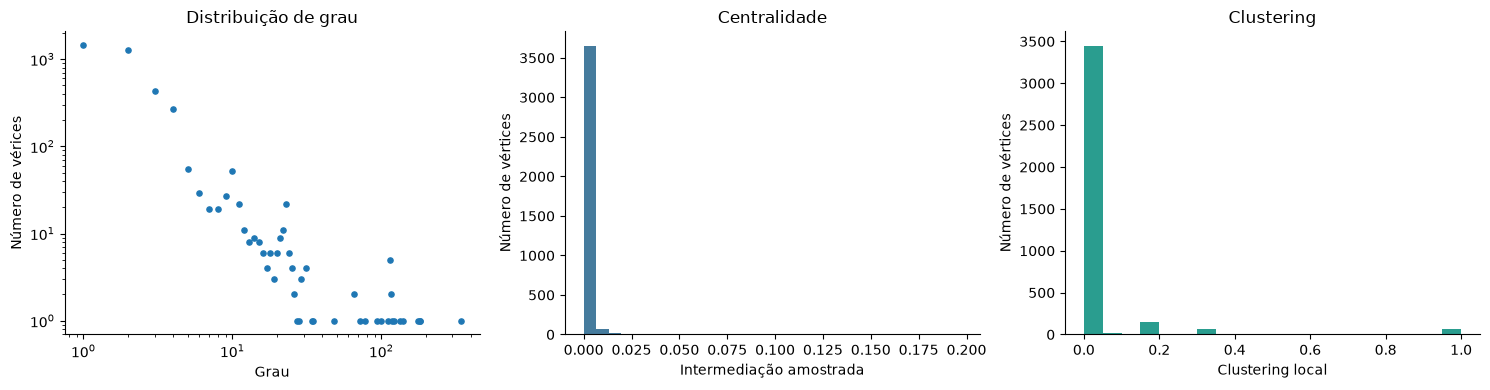

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
counts = degree.value_counts().sort_index()
axes[0].scatter(counts.index, counts.values, s=14)
axes[0].set(xscale="log", yscale="log", xlabel="Grau", ylabel="Número de vérices", title="Distribuição de grau")
axes[1].hist(betweenness, bins=30, color="#457b9d")
axes[1].set(xlabel="Intermediação amostrada", ylabel="Número de vértices", title="Centralidade")
axes[2].hist(clustering, bins=20, color="#2a9d8f")
axes[2].set(xlabel="Clustering local", ylabel="Número de vértices", title="Clustering")
plt.tight_layout(); plt.show()

## Comparação com redes sintéticas

ER sorteia arestas; WS parte de uma rede regular com religação; BA cresce com ligação preferencial. Comparamos mesmo número de vértices e grau médio aproximado; ER preserva exatamente o número de arestas. Um nulo adicional preserva a sequência de graus por trocas de arestas. Distâncias são médias de BFS em até 64 origens da maior componente. Três realizações resumem variação, mas não são um teste formal de classificação.

In [16]:
def summary(graph, seed):
    component = graph.subgraph(max(nx.connected_components(graph), key=len))
    origins = random.Random(seed).sample(list(component), min(64, len(component)))
    distances = []
    for origin in origins:
        lengths = nx.single_source_shortest_path_length(component, origin)
        distances.append(sum(lengths.values()) / max(len(component) - 1, 1))
    return {"arestas": graph.number_of_edges(), "clustering": nx.average_clustering(graph),
            "distância média": np.mean(distances), "maior componente": len(component) / len(graph)}

n, m = len(H), H.number_of_edges()
k = max(2, 2 * round(m / n))
ba_m = max(1, round(m / n))
rows = [{"modelo": "Terraria", **summary(H, SEED)}]
for repetition in range(3):
    seed = SEED + repetition
    for name in ["ER", "WS", "BA", "Nulo de graus"]:
        if name == "ER":
            graph = nx.gnm_random_graph(n, m, seed=seed)
        elif name == "WS":
            graph = nx.watts_strogatz_graph(n, k, .1, seed=seed)
        elif name == "BA":
            graph = nx.barabasi_albert_graph(n, ba_m, seed=seed)
        else:
            graph = H.copy()
            nx.double_edge_swap(graph, nswap=3*m, max_tries=100*m, seed=seed)
        rows.append({"modelo": name, **summary(graph, seed)})
        del graph
comparison = pd.DataFrame(rows)
means = comparison.groupby("modelo").mean()
display(means.round(4))
print(f"WS: k={k}, β=0,1; BA: m={ba_m}; nulo: {3*m:,} trocas. Arestas aproximadas diferem entre modelos.")

,arestas,clustering,distância média,maior componente
modelo,,,,
BA,7542.0,0.0095,4.6305,1.0000
ER,6692.0,0.0007,6.5277,0.9667
Nulo de graus,6692.0,0.0451,4.1356,0.9446
Terraria,6692.0,0.0323,5.8467,0.9539
WS,7546.0,0.3705,10.8276,1.0000


WS: k=4, β=0,1; BA: m=2; nulo: 20,076 trocas. Arestas aproximadas diferem entre modelos.


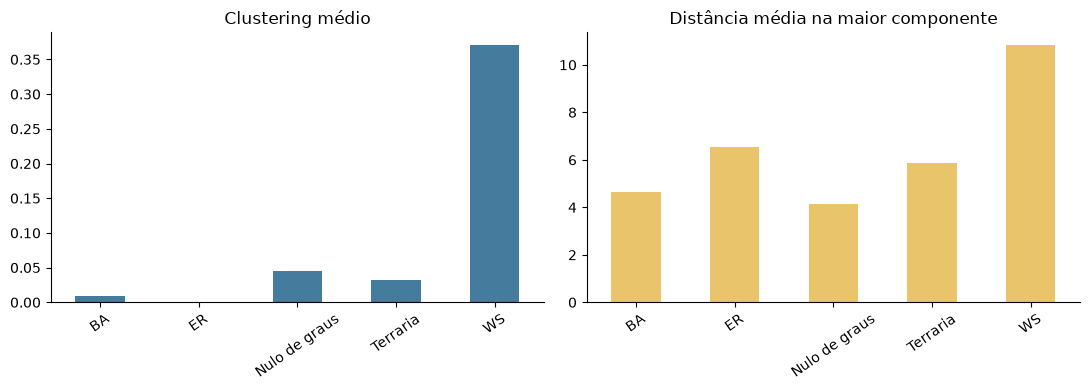

H tem clustering **0.0323**, contra ER **0.0007** e nulo de graus **0.0451**. As distâncias médias estimadas são **5.85** em H e **6.53** em ER. H apresenta heterogeneidade de grau, mas a figura não prova lei de potência; clustering e distâncias são evidências parciais, não prova de small-world ou aleatoriedade.

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
means["clustering"].plot.bar(ax=axes[0], color="#457b9d", title="Clustering médio")
means["distância média"].plot.bar(ax=axes[1], color="#e9c46a", title="Distância média na maior componente")
for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.show()
display(Markdown(f"H tem clustering **{means.loc['Terraria', 'clustering']:.4f}**, contra ER **{means.loc['ER', 'clustering']:.4f}** e nulo de graus **{means.loc['Nulo de graus', 'clustering']:.4f}**. As distâncias médias estimadas são **{means.loc['Terraria', 'distância média']:.2f}** em H e **{means.loc['ER', 'distância média']:.2f}** em ER. H apresenta heterogeneidade de grau, mas a figura não prova lei de potência; clustering e distâncias são evidências parciais, não prova de small-world ou aleatoriedade."))

## Robustez, difusão e navegação

Removemos itens aleatoriamente (média de cinco ordens) ou por grau inicial decrescente; a medida é a maior componente em relação ao tamanho original. BFS modela alcance topológico, sem afirmar que uma receita pode ser concluída. Pontes e articulações indicam fragilidade; ciclos e caminhos alternativos podem preservar conectividade, mas a preservação do conteúdo depende de um modelo de armazenamento que estes dados não fornecem.

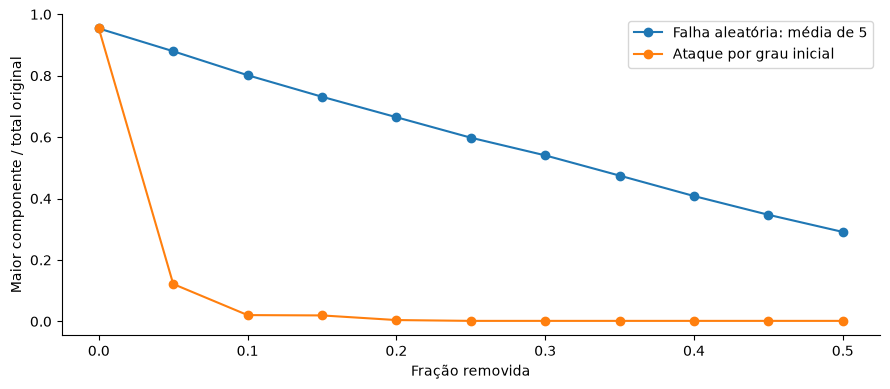

Com 10% removidos: aleatória 80.2%; ataque por grau 2.0% do total original.


In [18]:
fractions = np.linspace(0, .5, 11)
def removal_curve(order):
    graph = H.copy()
    values = []
    removed = 0
    for fraction in fractions:
        count = int(fraction * len(H))
        graph.remove_nodes_from(order[removed:count])
        removed = count
        values.append(len(max(nx.connected_components(graph), key=len, default=set())) / len(H))
    return np.array(values)

random_curves = []
for repetition in range(5):
    order = list(H)
    random.Random(SEED + repetition).shuffle(order)
    random_curves.append(removal_curve(order))
random_mean = np.mean(random_curves, axis=0)
targeted = removal_curve(sorted(H, key=H.degree, reverse=True))
plt.plot(fractions, random_mean, marker="o", label="Falha aleatória: média de 5")
plt.plot(fractions, targeted, marker="o", label="Ataque por grau inicial")
plt.xlabel("Fração removida"); plt.ylabel("Maior componente / total original")
plt.legend(); plt.tight_layout(); plt.show()
print(f"Com 10% removidos: aleatória {random_mean[2]:.1%}; ataque por grau {targeted[2]:.1%} do total original.")

In [19]:
origins = random.Random(SEED).sample(list(H), min(64, len(H)))
reach = []
for origin in origins:
    reach.append(len(nx.single_source_shortest_path_length(H, origin)) / len(H))
bridges = sum(1 for _ in nx.bridges(H))
articulations = sum(1 for _ in nx.articulation_points(H))
print(f"BFS: alcance médio de {np.mean(reach):.1%} dos vértices em 64 origens; distância média na maior componente {means.loc['Terraria', 'distância média']:.2f} arestas.")
print(f"Há {bridges:,} pontes e {articulations:,} articulações. Componentes desconectadas impedem difusão global.")

BFS: alcance médio de 86.5% dos vértices em 64 origens; distância média na maior componente 5.85 arestas.
Há 1,548 pontes e 446 articulações. Componentes desconectadas impedem difusão global.


In [20]:
names_top = ", ".join(top["item"])
display(Markdown(f"""## Conclusões calculadas

- **Vértices importantes:** {names_top}; o critério de consenso combina ligações diretas, intermediação e proximidade. Isso não é uma classificação de progresso no jogo.
- **Rede aleatória, livre de escala ou small-world?** H difere de ER nas métricas mostradas e tem hubs, mas as amostras não demonstram lei de potência. A comparação de clustering e caminhos com ER e com o nulo de graus fornece indícios, não prova conclusiva de small-world.
- **Robustez:** com 10% removidos, a maior componente conserva {random_mean[2]:.1%} dos itens originais em falhas aleatórias e {targeted[2]:.1%} em ataque por grau; a resistência depende do tipo de falha.
- **Difusão:** o alcance médio amostrado é {np.mean(reach):.1%}; componentes desconectadas limitam a difusão global. Não é uma simulação temporal ou de fabricação.
- **Preservação:** {bridges:,} pontes e {articulations:,} articulações revelam pontos frágeis; ciclos oferecem rotas alternativas, mas a topologia isolada não prova preservação de conteúdo.
- **Navegação:** na maior componente, a distância média estimada é {means.loc['Terraria', 'distância média']:.2f} arestas; outras componentes são inalcançáveis. Relações não dirigidas são associações, não instruções completas de crafting.

Na versão anterior, H tinha 3.773 vértices e 6.692 arestas. Agora tem {len(H):,} e {H.number_of_edges():,}; diferenças decorrem da seleção ou projeção, não de mudança dos JSONs. O marco de disponibilidade é estimado, lojas e drops têm condições por rota, e mineração não possui regra estruturada completa."""))

## Conclusões calculadas

- **Vértices importantes:** Torch, Iron Bar, Lead Bar; o critério de consenso combina ligações diretas, intermediação e proximidade. Isso não é uma classificação de progresso no jogo.
- **Rede aleatória, livre de escala ou small-world?** H difere de ER nas métricas mostradas e tem hubs, mas as amostras não demonstram lei de potência. A comparação de clustering e caminhos com ER e com o nulo de graus fornece indícios, não prova conclusiva de small-world.
- **Robustez:** com 10% removidos, a maior componente conserva 80.2% dos itens originais em falhas aleatórias e 2.0% em ataque por grau; a resistência depende do tipo de falha.
- **Difusão:** o alcance médio amostrado é 86.5%; componentes desconectadas limitam a difusão global. Não é uma simulação temporal ou de fabricação.
- **Preservação:** 1,548 pontes e 446 articulações revelam pontos frágeis; ciclos oferecem rotas alternativas, mas a topologia isolada não prova preservação de conteúdo.
- **Navegação:** na maior componente, a distância média estimada é 5.85 arestas; outras componentes são inalcançáveis. Relações não dirigidas são associações, não instruções completas de crafting.

Na versão anterior, H tinha 3.773 vértices e 6.692 arestas. Agora tem 3,773 e 6,692; diferenças decorrem da seleção ou projeção, não de mudança dos JSONs. O marco de disponibilidade é estimado, lojas e drops têm condições por rota, e mineração não possui regra estruturada completa.